# Salary Prediction

Corresponding  with this notebook is a slide deck where you will need to update all the portions in red.  Completing the notebook will provide all the results needed for the slides.  **Correctly completing the slides is a required part of the project.**


## Table of Contents
- [Introduction](#intro)
- [Part I - Descriptive Statistics](#descriptive)
- [Part II - Regression](#regression)
- [Part III - Interpret Results](#interpret)


<a id='intro'></a>
### Introduction

Linear Regression is very commonly performed by data analysts and data scientists.  For this project, you will be working to understand the results of a Linear Regression model associated with salaries.  Your goal is to work through this notebook to understand what variables are related to salary, and how exactly they are related.

As a final check, assure you meet all the criteria on the rubric.

<a id='descriptive'></a>
#### Part I - Descriptive Statistics

To get started, let's import our libraries.

In [1]:
import pandas as pd
import numpy as np
import random
import matplotlib.pyplot as plt
import statsmodels.api as sm
import seaborn as sb

random.seed(0)

For each of the parts of question `1` notice links to [pandas documentation](https://pandas.pydata.org/) is provided to assist with answering the questions.  Though there are other ways you could solve the questions, the documentation is provided to assist you with one fast way to find the answer to each question.


`1.a)` Now, read in the `salary_data.csv` data. Store it in `df`. Read in the dataset and take a look at the top few rows here. **This question is completed for you**:

In [2]:
df = pd.read_csv("data/salary_data.csv")
df.head()

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0


`b)` Use the below cell to find the number of rows in the dataset. [Helpful pandas link - `Dataframe.shape`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.shape.html#pandas.DataFrame.shape)

In [3]:
print(f"rows: {len(df)}")

rows: 375


`c)` Do any of the rows have missing values? [Helpful Pandas Link One](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.isnull.html) and [Helpful Pandas Link Two](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.sum.html)  

If there are missing values, determine a method for dealing with them.

In [4]:
print(df.isna().any())
print(df[df.isna().any(axis=1)].head())

Age                    True
Gender                 True
Education Level        True
Job Title              True
Years of Experience    True
Salary                 True
dtype: bool
     Age Gender Education Level Job Title  Years of Experience  Salary
172  NaN    NaN             NaN       NaN                  NaN     NaN
260  NaN    NaN             NaN       NaN                  NaN     NaN


In [5]:
# all rows containing NaN values are completely empty, no data will be lost if dropped
# dropping and re-indexing as index seems to just be a row counter, not captured data
df.dropna(inplace=True, ignore_index=True)
print(df.isna().any())
print(f"rows: {len(df)}")

Age                    False
Gender                 False
Education Level        False
Job Title              False
Years of Experience    False
Salary                 False
dtype: bool
rows: 373


`d)` How many employees are in each `Education Level`? Build a bar chart to show the count of employees in each level.

In [6]:
df["Education Level"].value_counts()

Education Level
Bachelor's    224
Master's       98
PhD            51
Name: count, dtype: int64

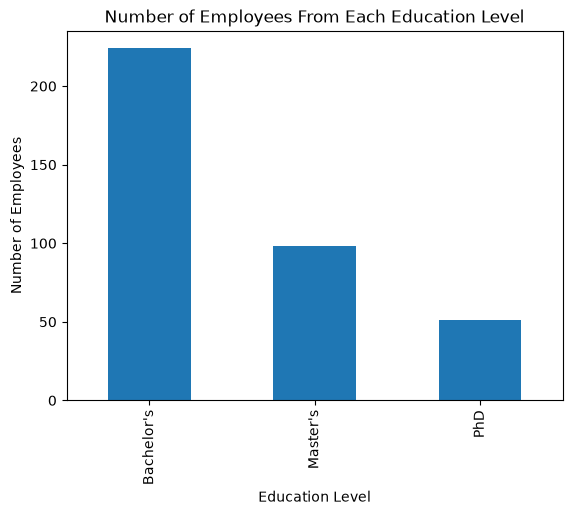

In [7]:
# bar chart of results - this part is done for you
df["Education Level"].value_counts().plot(kind="bar")
plt.title("Number of Employees From Each Education Level")
plt.ylabel("Number of Employees")
plt.show()

`e)` What are the possible values for `Salary`?  What does the distribution of `Salary` look like?

In [8]:
# print(df["Salary"].value_counts())
print("Salary:")
print(f"unique values: {df['Salary'].nunique()}")
print(f"range: ${df['Salary'].min()} - ${df['Salary'].max()}")

# is Salary  of $350 an outlier or a corrupt record?
print("\n$350 salary outlier:")
print(df.query("Salary == 350").T)
# looks legit, possibly gig work


Salary:
unique values: 36
range: $350.0 - $250000.0

$350 salary outlier:
                                                    258
Age                                                29.0
Gender                                             Male
Education Level                              Bachelor's
Job Title            Junior Business Operations Analyst
Years of Experience                                 1.5
Salary                                            350.0


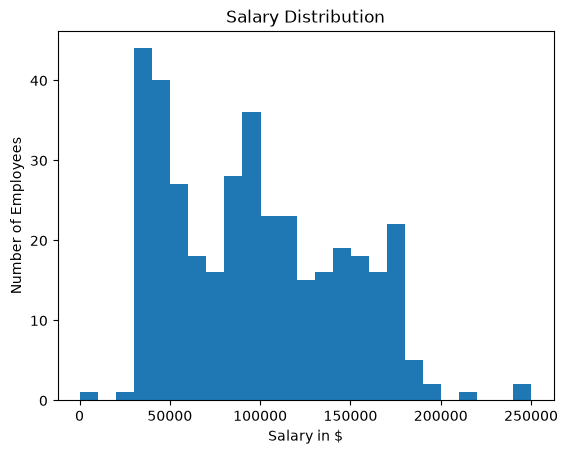

In [9]:
salary_hist_ax = df.plot.hist(column=["Salary"], bins=25, legend=False)
salary_hist_ax.set_xlabel("Salary in $")
salary_hist_ax.set_ylabel("Number of Employees")
salary_hist_ax.set_title("Salary Distribution")
plt.show()

<a id='regression'></a>
#### Part II - Regression

`1.` Now that you have had a chance to learn more about the dataset, let's look more at how different factors are related to `Salary`.

`a)` Consider average salary by gender, is there evidence that salaries are higher for one gender over the other?

In [10]:
df.groupby("Gender")["Salary"].describe()

,count,mean,std,min,25%,50%,75%,max
Gender,,,,,,,,
Female,179.0,97011.173184,45916.141054,35000.0,50000.0,90000.0,140000.0,190000.0
Male,194.0,103867.783505,50182.461438,350.0,60000.0,97500.0,140000.0,250000.0


`b)` Consider average salary by education level, is there evidence that salaries are higher for increased education?

In [11]:
df_edu_desc = df.groupby("Education Level")["Salary"].describe()[["mean", "50%"]]
df_edu_desc.style.format('${:.2f}')

,mean,50%
Education Level,,
Bachelor's,$74756.03,$65000.00
Master's,$129795.92,$120000.00
PhD,$157843.14,$155000.00


`c)` Consider average salary by years of experience, is there evidence that salaries are associated with increased years of experience?

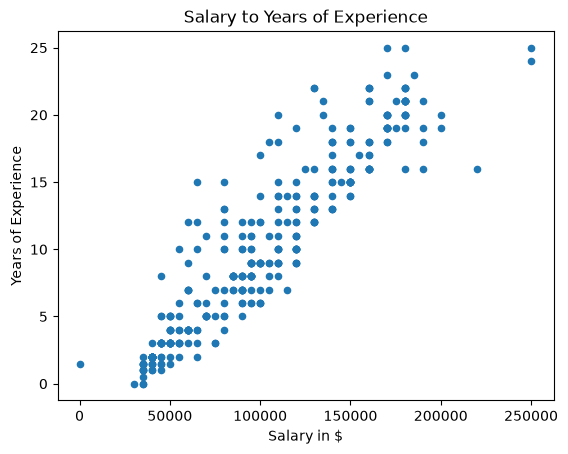

In [ ]:
salary_to_exp_ax = df.plot.scatter(["Salary"], ["Years of Experience"])
salary_to_exp_ax.set_xlabel("Salary in $")
salary_to_exp_ax.set_ylabel("Years of Experience")
salary_to_exp_ax.set_title("Salary to Years of Experience")
plt.show()

`d)`  To make use of Job Title column lets create bool flag based on word existiance


List of words:

* Director
* Junior
* Senior
* Manager
* Analyst
* Engineer

**This question is completed for you**

In [13]:
flag_words = ["director", "junior", "senior", "manager", "analyst", "engineer"]
df["Job Title"] = df["Job Title"].str.lower()
job_titles = []

for word in flag_words:
    job_title = "is_" + word
    df[job_title] = df["Job Title"].str.contains(word)
    job_titles.append(job_title)

df = df.drop("Job Title", axis=1)

In [14]:
# search for rows that did not match any of the job title flag words
no_job_title_flag = ~df[job_titles].any(axis=1)
print(
    f"{no_job_title_flag.sum()} of {len(df)} rows match none of the job title flag words"
)

46 of 373 rows match none of the job title flag words


`e)` Create a flag for gender where 1 is if a person is male and 0 if the person is not.

In [15]:
df = df.join(pd.get_dummies(df["Gender"], dtype=int))

`f)` Use statsmodels to fit a linear model to predict salary using each of the features from `a-e`.  These include:
* Gender
* Job TItle
* Years of Experience
* Education

In [16]:
# predictor variables and baselines
df = df.join(pd.get_dummies(df["Education Level"], dtype=int))
df["intercept"] = 1
df.head()

,Age,Gender,Education Level,Years of Experience,Salary,is_director,is_junior,is_senior,is_manager,is_analyst,is_engineer,Female,Male,Bachelor's,Master's,PhD,intercept
0,32.0,Male,Bachelor's,5.0,90000.0,False,False,False,False,False,True,0,1,1,0,0,1
1,28.0,Female,Master's,3.0,65000.0,False,False,False,False,True,False,1,0,0,1,0,1
2,45.0,Male,PhD,15.0,150000.0,False,False,True,True,False,False,0,1,0,0,1,1
3,36.0,Female,Bachelor's,7.0,60000.0,False,False,False,False,False,False,1,0,1,0,0,1
4,52.0,Male,Master's,20.0,200000.0,True,False,False,False,False,False,0,1,0,1,0,1


In [17]:
education_levels = list(df["Education Level"].unique())

# verify baselines will represent a significant sample
# job_title will not have a baseline since the categorization was not exhaustive
# so the job_title related columns are linearly independent
print(df.groupby(["Gender"])["Education Level"].value_counts())

gender_baseline = "Female"
education_level_baseline = "Bachelor's"
education_levels.remove(education_level_baseline)
print(f"baseline columns: '{gender_baseline}', '{education_level_baseline}'")

predictors = (
    ["intercept", "Male", "Years of Experience"] + education_levels + job_titles
)
print(f"predictors: {predictors}")

Gender  Education Level
Female  Bachelor's         103
        Master's            50
        PhD                 26
Male    Bachelor's         121
        Master's            48
        PhD                 25
Name: count, dtype: int64
baseline columns: 'Female', 'Bachelor's'
predictors: ['intercept', 'Male', 'Years of Experience', "Master's", 'PhD', 'is_director', 'is_junior', 'is_senior', 'is_manager', 'is_analyst', 'is_engineer']


In [18]:
# drop $350 salary outlier

df = df[df["Salary"] > 350]

In [19]:
salary_model = sm.OLS(df["Salary"], df[predictors])
salary_model_results = salary_model.fit()
salary_model_results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Salary   R-squared:                       0.917
Model:                            OLS   Adj. R-squared:                  0.914
Method:                 Least Squares   F-statistic:                     396.3
Date:                Sat, 17 Oct 2026   Prob (F-statistic):          7.55e-188
Time:                        13:38:46   Log-Likelihood:                -4075.5
No. Observations:                 372   AIC:                             8173.
Df Residuals:                     361   BIC:                             8216.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
=======================================================================================
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
intercept              3.2e+04   2458.521     13.014      0.000    2.72e+04    3.68e+04
Male                 7676.6582   1494.609      5.136      0.000    4737.424    1.06e+04
Years of Experience  4928.4788    195.393     25.223      0.000    4544.227    5312.730
Master's             1.346e+04   2031.258      6.628      0.000    9468.287    1.75e+04
PhD                  2.338e+04   2771.286      8.436      0.000    1.79e+04    2.88e+04
is_director          2.554e+04   3496.600      7.305      0.000    1.87e+04    3.24e+04
is_junior           -4156.5912   2433.955     -1.708      0.089   -8943.104     629.921
is_senior            1.302e+04   1955.098      6.659      0.000    9174.774    1.69e+04
is_manager           4503.6322   1938.874      2.323      0.021     690.725    8316.539
is_analyst            406.1927   2089.609      0.194      0.846   -3703.142    4515.527
is_engineer          2371.1630   3522.702      0.673      0.501   -4556.433    9298.759
==============================================================================
Omnibus:                      141.271   Durbin-Watson:                   1.805
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1191.427
Skew:                           1.357   Prob(JB):                    1.93e-259
Kurtosis:                      11.337   Cond. No.                         63.1
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

<a id='interpretation'></a>
### Part III - Interpret Results

`1.` Consider you are tasked with finding which features in your linear model are significantly related to salary.  Were there any features that were not significantly related to salary in your first model?  If not, remove those features and fit a new model.  Only keep the features that were significant from the original model.

In [20]:
# explain your answer and fit a new model with the reduced set of features here
print("omitting insignificant predictor variables (p-value > 0.05):")

for p, v in salary_model_results.pvalues.items():
    if p != "intercept" and v > 0.05:
        print(f"  {p:<15}{v:.4f}")
        predictors.remove(p)

salary_model = sm.OLS(df["Salary"], df[predictors])
salary_model_results = salary_model.fit()
salary_model_results.summary2()

omitting insignificant predictor variables (p-value > 0.05):
  is_junior      0.0885
  is_analyst     0.8460
  is_engineer    0.5013


<class 'statsmodels.iolib.summary2.Summary'>
"""
                       Results: Ordinary least squares
=============================================================================
Model:                  OLS                 Adj. R-squared:        0.914     
Dependent Variable:     Salary              AIC:                   8170.4489 
Date:                   2026-10-17 13:38    BIC:                   8201.8000 
No. Observations:       372                 Log-Likelihood:        -4077.2   
Df Model:               7                   F-statistic:           564.9     
Df Residuals:           364                 Prob (F-statistic):    3.42e-191 
R-squared:              0.916               Scale:                 1.9813e+08
-----------------------------------------------------------------------------
                      Coef.     Std.Err.    t    P>|t|    [0.025     0.975]  
-----------------------------------------------------------------------------
intercept           29068.3747 1660.5939 17.5048 0.0000 25802.8125 32333.9368
Male                 7848.8370 1466.0753  5.3536 0.0000  4965.7961 10731.8779
Years of Experience  5081.2555  175.2972 28.9865 0.0000  4736.5331  5425.9780
Master's            13972.6859 2008.2683  6.9576 0.0000 10023.4212 17921.9506
PhD                 23137.0382 2728.3062  8.4804 0.0000 17771.8171 28502.2594
is_director         25052.4942 3461.8747  7.2367 0.0000 18244.7088 31860.2796
is_senior           14345.6036 1799.2920  7.9729 0.0000 10807.2914 17883.9159
is_manager           4174.9452 1801.4742  2.3175 0.0210   632.3416  7717.5489
-----------------------------------------------------------------------------
Omnibus:                 136.767          Durbin-Watson:             1.779   
Prob(Omnibus):           0.000            Jarque-Bera (JB):          1088.167
Skew:                    1.322            Prob(JB):                  0.000   
Kurtosis:                10.951           Condition No.:             61      
=============================================================================
Notes:
[1] Standard Errors assume that the covariance matrix of the errors is
correctly specified.
"""

In [21]:
model_coef = salary_model_results.params
model_conf_int = salary_model_results.conf_int()
standard_disclaimer = ", holding all other variables constant"

model_conf_int

,0,1
intercept,25802.812489,32333.936827
Male,4965.796119,10731.877921
Years of Experience,4736.533070,5425.977979
Master's,10023.421230,17921.950579
PhD,17771.817060,28502.259409
is_director,18244.708819,31860.279619
is_senior,10807.291356,17883.915900
is_manager,632.341554,7717.548905


`a)` With each additional year of experience, what is the expected change in salary?  What is the 95% confidence interval of the change?

In [22]:
print("Answer:")
print(
    f"+ ${model_coef['Years of Experience']:.2f} per year of experience{standard_disclaimer}"
)
print(
    f"95% confidence interval: ${model_conf_int.loc['Years of Experience'][0]:.2f} - ${model_conf_int.loc['Years of Experience'][1]:.2f}"
)

Answer:
+ $5081.26 per year of experience, holding all other variables constant
95% confidence interval: $4736.53 - $5425.98


`b)` What is the expected difference in salary between someone with a senior title and someone with none of the other title indications?

In [23]:
print("Answer:")
print(f"+ ${model_coef['is_senior']:.2f}{standard_disclaimer}")

Answer:
+ $14345.60, holding all other variables constant


`c)` What is the expected difference in salary between someone with a PhD and an individual with no PhD nor master's degree?  What is the 95% confidence interval of the change?

In [24]:
print("Answer:")
print(
    f"+ ${model_coef['PhD']:.2f}{standard_disclaimer}"
)
print(
    f"95% confidence interval: ${model_conf_int.loc['PhD'][0]:.2f} - ${model_conf_int.loc['PhD'][1]:.2f}"
)

Answer:
+ $23137.04, holding all other variables constant
95% confidence interval: $17771.82 - $28502.26


`d)` If a male employee has 5 years of experience as a senior engineer with a bachelor's degree, what is the expected salary of the employee?

In [25]:
male_5_senior_bachelor = model_coef["intercept"] + model_coef["Male"] + (model_coef["Years of Experience"]*5) + model_coef["is_senior"]

print("Answer:")
print(f"expected salary: ${male_5_senior_bachelor:.2f}")

Answer:
expected salary: $76669.09


male, senior engineer, 5 years experience, bachelor's degree expected salary: **$76,359.11**

`e)` Imagine that the employee in question `d)` actually has a salary of $110,000, what would the residual be for this employee?

In [26]:
print("Answer:")
print(f"+ ${110000 - male_5_senior_bachelor:.2f}")

Answer:
+ $33330.91


`f)` How well do you think your model fits?  What metrics or plots would you consider to understand if this model does a good job of predicting salary?

In [27]:
### Your work here
print("Answer:")
print(f"R-squared: {salary_model_results.rsquared:4f}")

Answer:
R-squared: 0.915711


#### Investigate "Years of Experience" Co-Linearities
Some of the variables in the model could have co-linear relationships with "Years of Experience"

__Suspected Variables__

- `is_director`
- `is_senior`
- `is_manager`
- `Master's`
- `PhD`

These are violin plots that compare the "Years of Experience" distribution in relation to the suspected variables. Note that a True value in each has a distribution that is noticeably shifted toward higher "Years of Experience" values.

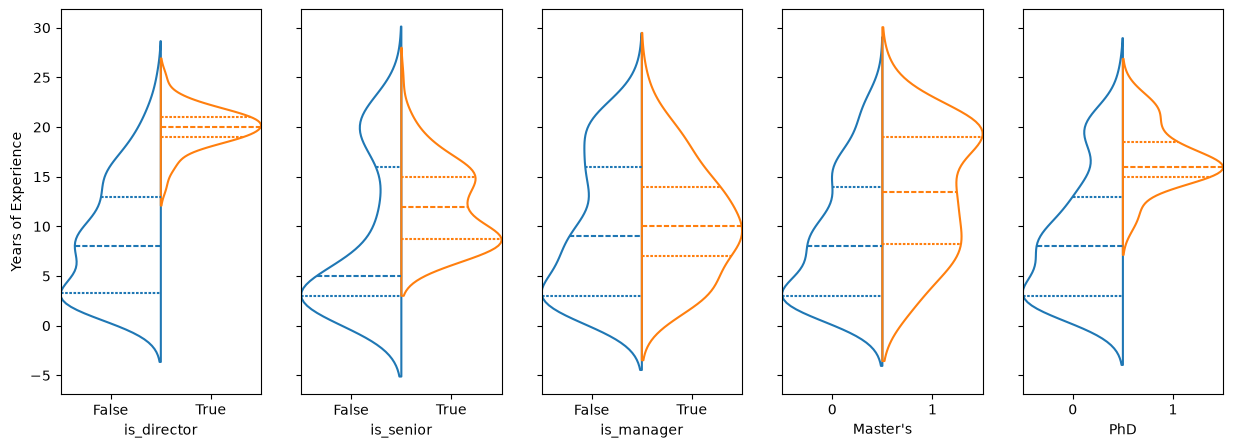

In [84]:
# violin plots of suspected variables (True vs False) and mean Years of Experience
fig, (ax1, ax2, ax3, ax4, ax5) = plt.subplots(1, 5, sharey=True, figsize=(15, 5))

sb.violinplot(
    data=df,
    x="is_director",
    y="Years of Experience",
    ax=ax1,
    fill=False,
    inner="quart",
    split=True,
    hue="is_director",
    legend=False,
    gap=0,
    width=1
)
sb.violinplot(
    data=df,
    x="is_senior",
    y="Years of Experience",
    ax=ax2,
    fill=False,
    inner="quart",
    split=True,
    hue="is_senior",
    legend=False,
    gap=0,
    width=1,
)
sb.violinplot(
    data=df,
    x="is_manager",
    y="Years of Experience",
    ax=ax3,
    fill=False,
    inner="quart",
    split=True,
    hue="is_manager",
    legend=False,
    gap=0,
    width=1,
)
sb.violinplot(
    data=df,
    x="Master's",
    y="Years of Experience",
    ax=ax4,
    fill=False,
    inner="quart",
    split=True,
    hue="Master's",
    legend=False,
    gap=0,
    width=1,
)
sb.violinplot(
    data=df,
    x="PhD",
    y="Years of Experience",
    ax=ax5,
    fill=False,
    inner="quart",
    split=True,
    hue="PhD",
    legend=False,
    gap=0,
    width=1,
)
plt.show()


Running a linear regression model of experience and training level related variables to `Years of Experience` reveals statistically significant relationships. This is likely affecting the quality of the `Salary` linear regression model results.

| suspected variable | p-value |
| --- | --- |
| `Master's` | 0.000 |
| `PhD` | 0.000 |
| `is_director` | 0.000 |
| `is_senior` | 0.000 |
| `is_manager` | 0.000 |

R-squared: __0.595__

All have p-values of __0.000__ when used as predictor variables against `Years of Experience` and the regression as a whole returns an R-squared value of __0.595__ indicating these 5 predictor variables explain 59.5% of the variance of `Years of Experience` in the dataset.

In [ ]:
years_predictors = predictors.copy()
years_predictors.remove("Years of Experience")
years_predictors.remove("Male")
years_multicolinearity_model = sm.OLS(df["Years of Experience"], df[years_predictors])
years_multicolinearity_model_results = years_multicolinearity_model.fit()
years_multicolinearity_model_results.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                             OLS Regression Results                            
===============================================================================
Dep. Variable:     Years of Experience   R-squared:                       0.595
Model:                             OLS   Adj. R-squared:                  0.589
Method:                  Least Squares   F-statistic:                     107.4
Date:                 Sat, 17 Oct 2026   Prob (F-statistic):           1.41e-69
Time:                         13:38:46   Log-Likelihood:                -1058.5
No. Observations:                  372   AIC:                             2129.
Df Residuals:                      366   BIC:                             2153.
Df Model:                            5                                         
Covariance Type:             nonrobust                                         
===============================================================================
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
intercept       4.8252      0.357     13.520      0.000       4.123       5.527
Master's        2.6187      0.582      4.501      0.000       1.475       3.763
PhD             7.2576      0.719     10.093      0.000       5.844       8.672
is_director    11.5747      0.836     13.840      0.000       9.930      13.219
is_senior       3.7267      0.500      7.454      0.000       2.744       4.710
is_manager      2.7672      0.517      5.349      0.000       1.750       3.785
==============================================================================
Omnibus:                      114.033   Durbin-Watson:                   2.176
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              308.397
Skew:                           1.457   Prob(JB):                     1.08e-67
Kurtosis:                       6.378   Cond. No.                         5.35
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [45]:
years_gender_only_model = sm.OLS(df["Salary"], df[["intercept", "Years of Experience", "Male"]])
years_gender_only_model_results = years_gender_only_model.fit()
years_gender_only_model_results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Salary   R-squared:                       0.871
Model:                            OLS   Adj. R-squared:                  0.870
Method:                 Least Squares   F-statistic:                     1247.
Date:                Sat, 17 Oct 2026   Prob (F-statistic):          7.21e-165
Time:                        14:38:45   Log-Likelihood:                -4156.3
No. Observations:                 372   AIC:                             8319.
Df Residuals:                     369   BIC:                             8330.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
=======================================================================================
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
intercept            2.875e+04   1884.683     15.253      0.000     2.5e+04    3.25e+04
Years of Experience  6818.7604    137.031     49.761      0.000    6549.300    7088.220
Male                 6833.2126   1794.195      3.809      0.000    3305.082    1.04e+04
==============================================================================
Omnibus:                       37.937   Durbin-Watson:                   1.777
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              103.013
Skew:                          -0.466   Prob(JB):                     4.28e-23
Kurtosis:                       5.403   Cond. No.                         30.2
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

**Your Answer Here**

<a id='finalcheck'></a>
## Final Check!

Congratulations!  You have reached the end of the salary prediction project!  You should be very proud of all you have accomplished!

> **Tip**: Once you are satisfied with your work here, check over your notebook to make sure that it satisfies all the specifications mentioned in the rubric. You should also probably remove all of the "Hints" and "Tips" like this one so that the presentation is as polished as possible.


<a id='submission'></a>
## Submission

Please follow the directions in the classroom to submit this notebook, as well as your completed slides.